# FaceUnlock: face verification CNN

Pipeline: data setup, EDA, preprocessing, model training, evaluation.

Runs on a Mac (cheap cells, local data) and on Google Colab (training, data from Kaggle).

## 0. Imports

All libraries used in the notebook are imported here, once.

In [1]:
import random
import sys
import warnings
from pathlib import Path

# Set before third-party imports: some warn while importing.
warnings.filterwarnings("ignore")

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

## 1. Setup and data location

`IN_COLAB` is `True` only on Colab. On Colab we download LFW (Labeled Faces in the Wild) from Kaggle; locally we use the copy in `data/lfw`.

In [2]:
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    LFW_ROOT = Path(kagglehub.dataset_download("jessicali9530/lfw-dataset"))
else:
    LFW_ROOT = Path("../data/lfw")

FACES_DIR = LFW_ROOT / "lfw-deepfunneled" / "lfw-deepfunneled"
print(FACES_DIR, "exists:", FACES_DIR.exists())

../data/lfw/lfw-deepfunneled/lfw-deepfunneled exists: True


## 2. EDA: photos per person (LFW)

Face verification needs several photos of the same person. This shows how many people have enough.

count    5749.000000
mean        2.301792
std         9.016410
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       530.000000
dtype: float64
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Ariel_Sharon          77
Hugo_Chavez           71
Junichiro_Koizumi     60
Jean_Chretien         55
John_Ashcroft         53
dtype: int64
People with 2+ photos: 1680


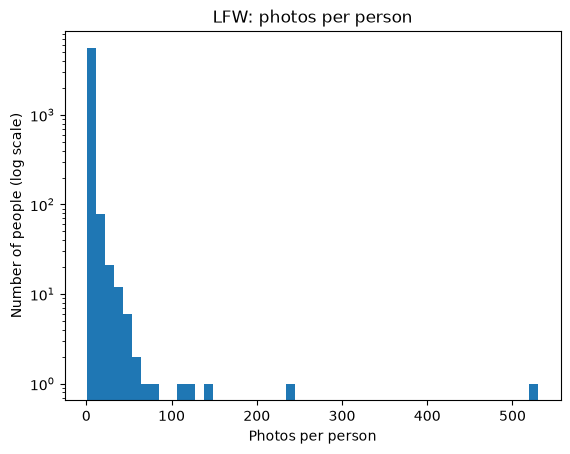

In [3]:
counts = pd.Series(
    {p.name: len(list(p.glob("*.jpg"))) for p in FACES_DIR.iterdir() if p.is_dir()}
).sort_values(ascending=False)

print(counts.describe())
print(counts.head(10))
print("People with 2+ photos:", (counts >= 2).sum())

counts.plot(kind="hist", bins=50, log=True)
plt.xlabel("Photos per person")
plt.ylabel("Number of people (log scale)")
plt.title("LFW: photos per person")
plt.show()

## 3. EDA: sample LFW faces

Two photos each of eight random people (one column per person), plus the size and colour mode of a photo.

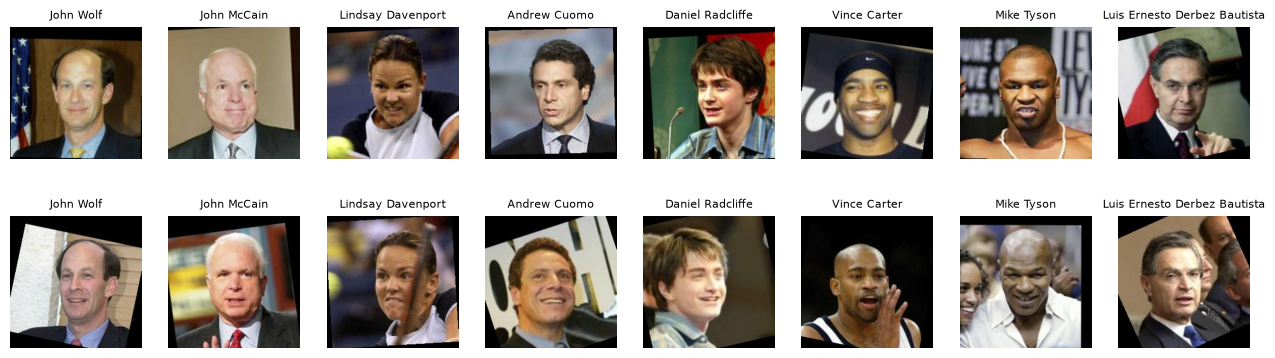

size: (250, 250) mode: RGB


In [4]:
random.seed(42)
people = counts[counts >= 2].index.tolist()
picked = random.sample(people, 8)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for col, name in enumerate(picked):
    photos = sorted((FACES_DIR / name).glob("*.jpg"))[:2]
    for row, photo in enumerate(photos):
        axes[row, col].imshow(Image.open(photo))
        axes[row, col].set_title(name.replace("_", " "), fontsize=8)
        axes[row, col].axis("off")
plt.show()

sample = Image.open(next(FACES_DIR.glob("*/*.jpg")))
print("size:", sample.size, "mode:", sample.mode)

## 4. EDA: Kaggle Human Faces (strangers set)

This set has no identities. We use it for dashboard visuals, look-alikes and extra strangers when testing false accepts. We measure image sizes, colour modes and brightness on a random sample of 1000.

Total images: 7219


             width       height   brightness
count  1000.000000  1000.000000  1000.000000
mean    887.690000  1073.192000   120.282918
std     742.842819   880.155552    38.938555
min     236.000000   236.000000    31.028550
25%     600.000000   600.000000    90.338084
50%     633.000000   827.000000   118.445199
75%     948.750000  1104.000000   146.606006
max    7680.000000  7360.000000   232.628058
mode
RGB     969
L        18
RGBA     12
P         1
Name: count, dtype: int64


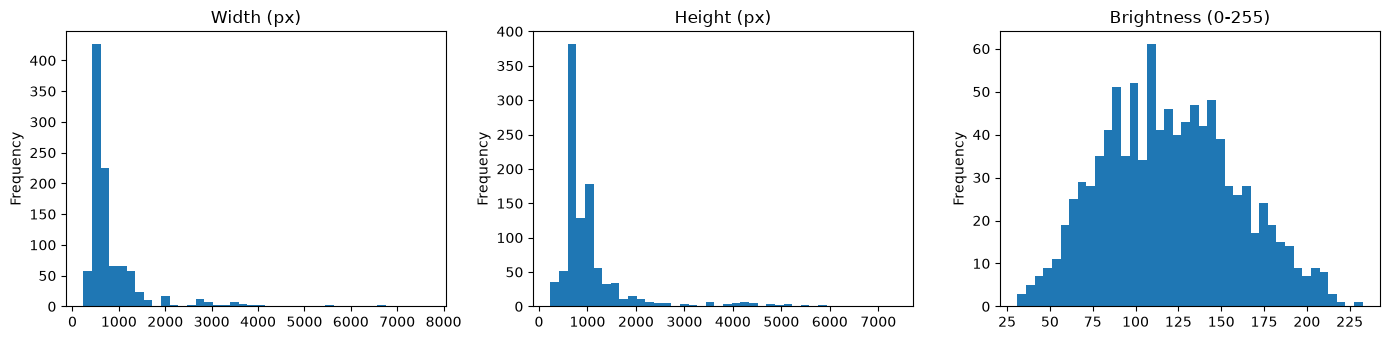

In [5]:
if IN_COLAB:
    HUMANS_DIR = Path(kagglehub.dataset_download("ashwingupta3012/human-faces")) / "Humans"
else:
    HUMANS_DIR = Path("../data/human-faces/Humans")

files = [p for p in HUMANS_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print("Total images:", len(files))

rows = []
for f in random.sample(files, 1000):
    with Image.open(f) as im:
        gray = np.asarray(im.convert("L"))
        rows.append({"width": im.width, "height": im.height,
                     "mode": im.mode, "brightness": gray.mean()})
stats = pd.DataFrame(rows)

print(stats.describe())
print(stats["mode"].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
stats["width"].plot(kind="hist", bins=40, ax=axes[0], title="Width (px)")
stats["height"].plot(kind="hist", bins=40, ax=axes[1], title="Height (px)")
stats["brightness"].plot(kind="hist", bins=40, ax=axes[2], title="Brightness (0-255)")
plt.tight_layout()
plt.show()